Max implied daily deaths/million (from cumulative): 12.88
Max in smoothed column: 12.88
Countries before dropping missing: 161
Countries in model: 137
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -864.0040   1053.511     -0.820      0.414   -2947.953    1219.945
median_age   165.6604     21.840      7.585      0.000     122.458     208.863
log_gdp     -175.7937    158.713     -1.108      0.270    -489.744     138.157
beds        -108.7989     53.548     -2.032      0.044    -214.722      -2.876
vax          -13.2328      4.728     -2.799      0.006     -22.585      -3.880
R-squared: 0.52
                deaths_pm    pred   resid
country                                  
Brazil             3339.0  1563.0  1776.0
Germany            2081.0  2831.0  -750.0
India               373.0  1046.0  -672.0
Japan               598.0  2818.0 -2221.0
Sweden             2342.0  2

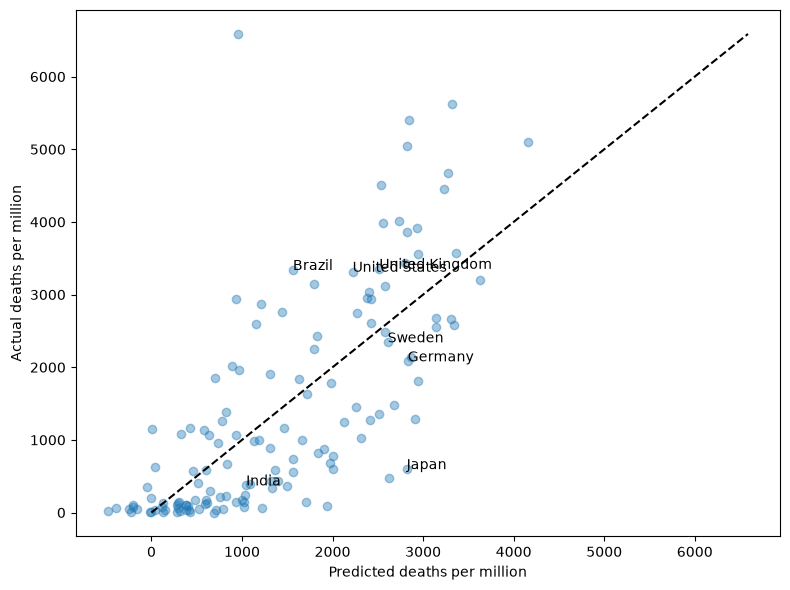

In [1]:
import pandas as pd, numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

raw = pd.read_csv("../data/owid_raw.csv", parse_dates=["date"])

# --- Japan check: implied daily deaths from the cumulative series vs. the spike ---
jp = (raw[(raw["country"] == "Japan") & raw["date"].between("2023-01-01", "2023-03-31")]
      .set_index("date"))
implied = jp["total_deaths_per_million"].diff(7) / 7
print("Max implied daily deaths/million (from cumulative):", round(implied.max(), 2))
print("Max in smoothed column:", round(jp["new_deaths_smoothed_per_million"].max(), 2))

# --- Build one row per country ---
c = raw[raw["continent"].notna() & (raw["date"] <= "2023-06-30")].sort_values("date")
g = c.groupby("country")
cs = pd.DataFrame({
    "deaths_pm": g["total_deaths_per_million"].last(),   # last non-null value
    "vax": g["people_fully_vaccinated_per_hundred"].max(),
    "median_age": g["median_age"].first(),
    "gdp": g["gdp_per_capita"].first(),
    "beds": g["hospital_beds_per_thousand"].first(),
    "pop": g["population"].first(),
})
cs = cs[cs["pop"] > 1_000_000]
print("Countries before dropping missing:", len(cs))
m = cs.dropna().copy()
print("Countries in model:", len(m))
m["log_gdp"] = np.log(m["gdp"])

# --- Regression ---
model = smf.ols("deaths_pm ~ median_age + log_gdp + beds + vax", data=m).fit()
print(model.summary().tables[1])
print("R-squared:", round(model.rsquared, 2))

# --- Over/under-performers: actual minus predicted ---
m["pred"] = model.predict(m)
m["resid"] = m["deaths_pm"] - m["pred"]
focus = ["India", "United States", "Brazil", "United Kingdom",
         "Germany", "Japan", "South Africa", "Sweden"]
print(m.loc[m.index.isin(focus), ["deaths_pm", "pred", "resid"]].round(0))
print("Lower than expected:\n", m["resid"].nsmallest(5).round(0))
print("Higher than expected:\n", m["resid"].nlargest(5).round(0))

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(m["pred"], m["deaths_pm"], alpha=0.4)
for name in focus:
    if name in m.index:
        ax.annotate(name, (m.loc[name, "pred"], m.loc[name, "deaths_pm"]))
lim = [0, m[["pred", "deaths_pm"]].max().max()]
ax.plot(lim, lim, "k--")
ax.set_xlabel("Predicted deaths per million")
ax.set_ylabel("Actual deaths per million")
plt.tight_layout()
plt.show()

In [2]:
# Country-level table (for the map and over/under-performer chart)
m2 = m.copy()
m2["code"] = g["code"].first().reindex(m2.index)
m2 = m2.reset_index()
m2.to_csv("../data/country_summary.csv", index=False)

# Cleaned trend data for the 8 focus countries
sub = pd.read_csv("../data/covid_focus.csv", parse_dates=["date"])
END = pd.Timestamp("2023-06-30")
last_real = (sub[sub["new_deaths_smoothed_per_million"] > 0]
             .groupby("country")["date"].max().clip(upper=END))
trend = sub[(sub["date"] >= "2020-03-01") &
            (sub["date"] <= sub["country"].map(last_real))]
trend.to_csv("../data/covid_trend.csv", index=False)
print(m2.shape, trend.shape)

(137, 11) (9539, 12)


In [3]:
import pandas as pd
raw = pd.read_csv("../data/owid_raw.csv", parse_dates=["date"])
summ = pd.read_csv("../data/country_summary.csv")
cols = ["country", "continent", "date", "new_cases_smoothed_per_million", "new_deaths_smoothed_per_million", "total_deaths_per_million", "people_fully_vaccinated_per_hundred", "stringency_index", "population", "median_age", "gdp_per_capita", "hospital_beds_per_thousand"]
allc = raw[raw["country"].isin(summ["country"])][cols]
last_real = allc[allc["new_deaths_smoothed_per_million"] > 0].groupby("country")["date"].max().clip(upper=pd.Timestamp("2023-06-30"))
trend = allc[(allc["date"] >= "2020-03-01") & (allc["date"] <= allc["country"].map(last_real))]
trend.to_csv("../data/covid_trend.csv", index=False)
print(trend["country"].nunique(), trend.shape)

136 (152764, 12)


In [4]:
print(set(summ["country"]) - set(trend["country"]))

{'Turkmenistan'}
